# Ridge Regression 

In [6]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml

housing = fetch_openml(name="boston", version=1, as_frame=True)

df = housing.frame

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())



      CRIM    ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  PTRATIO  \
0  0.00632  18.0   2.31    0  0.538  6.575  65.2  4.0900   1  296.0     15.3   
1  0.02731   0.0   7.07    0  0.469  6.421  78.9  4.9671   2  242.0     17.8   
2  0.02729   0.0   7.07    0  0.469  7.185  61.1  4.9671   2  242.0     17.8   
3  0.03237   0.0   2.18    0  0.458  6.998  45.8  6.0622   3  222.0     18.7   
4  0.06905   0.0   2.18    0  0.458  7.147  54.2  6.0622   3  222.0     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  
Dataset shape: (506, 14)
Columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']


Use the existing dataset variables

In [7]:

# The target column in this dataset is MEDV
X = df.drop(columns=["MEDV"])
y = df["MEDV"].astype(float)

print("Features shape:", X.shape)
print("Target shape:", y.shape)



Features shape: (506, 13)
Target shape: (506,)


In [8]:

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ridge_pipeline = make_pipeline(StandardScaler(), Ridge())

params = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1, 5, 10, 20, 50, 100]
}

ridge_regressor = GridSearchCV(
    ridge_pipeline,
    params,
    scoring="neg_mean_squared_error",
    cv=5
)

ridge_regressor.fit(X_train, y_train)

ridge_prediction = ridge_regressor.predict(X_test)

print("Best Alpha:", ridge_regressor.best_params_["ridge__alpha"])
print("R² Score:", round(r2_score(y_test, ridge_prediction), 4))
print("MAE:", round(mean_absolute_error(y_test, ridge_prediction), 4))
print("MSE:", round(mean_squared_error(y_test, ridge_prediction), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, ridge_prediction)), 4))


Best Alpha: 1
R² Score: 0.6685
MAE: 3.1857
MSE: 24.3129
RMSE: 4.9308


Actual vs Predicted graph

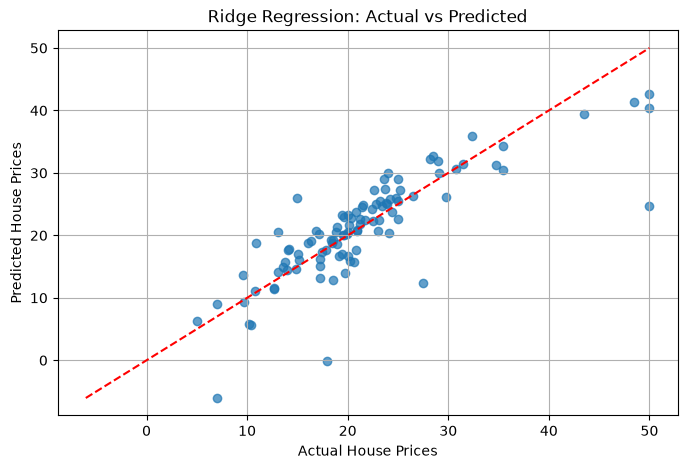

In [9]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, ridge_prediction, alpha=0.7)

min_val = min(np.min(y_test), np.min(ridge_prediction))
max_val = max(np.max(y_test), np.max(ridge_prediction))

plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Ridge Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


**Conclusion:**

Ridge Regression was successfully implemented for house price prediction using Python and Scikit-learn. GridSearchCV with 5-fold cross-validation selected the optimal alpha value of 1. The model achieved an R² score of 0.6685, MAE of 3.1857, MSE of 24.3129, and RMSE of 4.9308 on the test dataset. Compared with the Linear Regression baseline, Ridge Regression produced similar results, demonstrating that regularization did not significantly improve predictive performance for this particular train-test split.